# House Price Prediction

Predict the sale price of a house (`SalePrice`) from basic property details using **regression**.

**Workflow:** load data -> clean -> feature engineering -> train/test split -> train models -> evaluate (R2, MAE, RMSE, MAPE) -> error analysis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (r2_score, mean_absolute_error,
                             mean_squared_error, mean_absolute_percentage_error)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load data

In [2]:
df = pd.read_csv("HousePricepre.csv")
print("Shape:", df.shape)
df.head()

Shape: (2919, 13)


,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0


In [3]:
print(df.isnull().sum())

Id                 0
MSSubClass         0
MSZoning           4
LotArea            0
LotConfig          0
BldgType           0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
Exterior1st        1
BsmtFinSF2         1
TotalBsmtSF        1
SalePrice       1459
dtype: int64


## 2. Clean data

The CSV has 2,919 rows, but `SalePrice` is filled for only **1,460** of them (the rest is the unlabeled "test" part of the original Kaggle data).

- We **cannot** fill the target with the mean: that creates fake labels and the model is then "evaluated" on made-up values.
- So we keep only rows where `SalePrice` is known, and drop the `Id` column (it is just a row number).

In [4]:
df = df[df["SalePrice"].notna()].drop(columns=["Id"]).copy()
print("Rows with known SalePrice:", len(df))
print("Missing values left:", df.isnull().sum().sum())

Rows with known SalePrice: 1460
Missing values left: 0


## 3. Explore the target

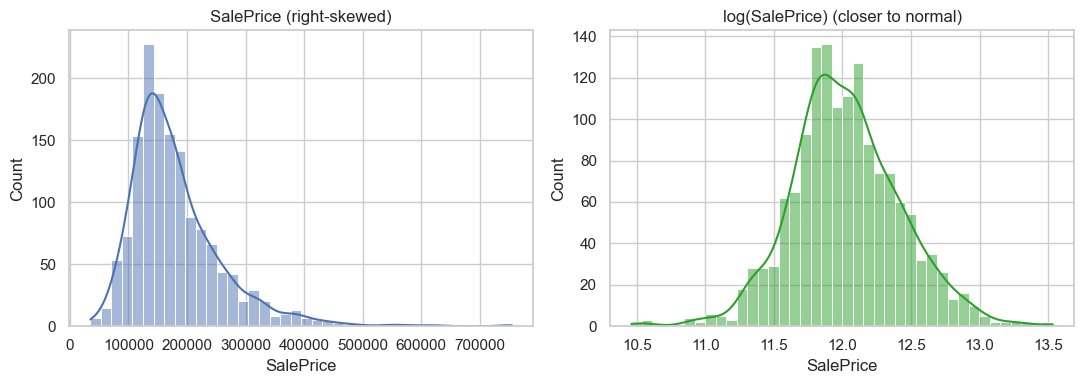

Skewness: 1.88


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["SalePrice"], bins=40, kde=True, ax=ax[0])
ax[0].set_title("SalePrice (right-skewed)")
sns.histplot(np.log1p(df["SalePrice"]), bins=40, kde=True, ax=ax[1], color="tab:green")
ax[1].set_title("log(SalePrice) (closer to normal)")
plt.tight_layout()
plt.show()
print("Skewness:", round(df["SalePrice"].skew(), 2))

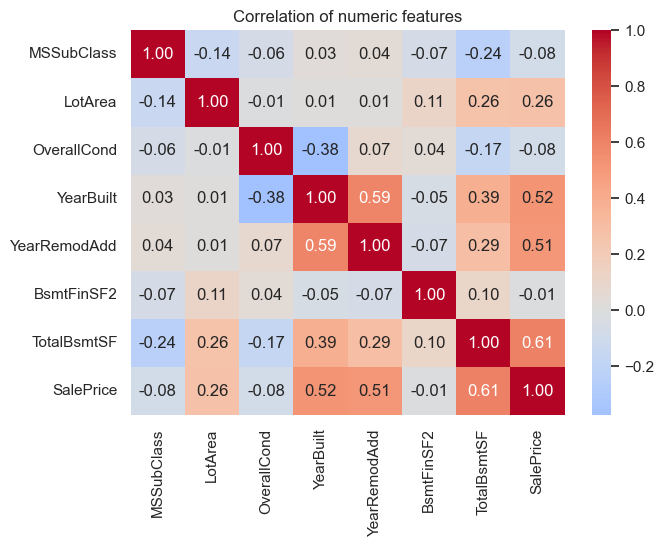

In [6]:
num_cols = df.select_dtypes("number").columns
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric features")
plt.show()

## 4. Feature engineering

- `MSSubClass` is a **building-type code** (20, 60, 70 ...), not a quantity, so it is treated as a category.
- `YearBuilt` / `YearRemodAdd` are converted to **house age** and **years since remodel**, which a linear model can use more naturally than raw years.
- Categorical columns are one-hot encoded.

In [7]:
REF_YEAR = 2010  # the dataset covers sales up to 2010

df["MSSubClass"] = df["MSSubClass"].astype(str)
df["HouseAge"] = REF_YEAR - df["YearBuilt"]
df["YearsSinceRemodel"] = REF_YEAR - df["YearRemodAdd"]
df["IsRemodeled"] = (df["YearBuilt"] != df["YearRemodAdd"]).astype(int)
df = df.drop(columns=["YearBuilt", "YearRemodAdd"])

X = pd.get_dummies(df.drop(columns="SalePrice"), drop_first=True)
y = df["SalePrice"]
print("Feature matrix:", X.shape)

Feature matrix: (1460, 47)


## 5. Train / test split (80 / 20)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1168, 47) | Test: (292, 47)


## 6. Train and compare models

1. **Linear Regression**: simple, interpretable baseline.
2. **Linear Regression on log(price)**: prices are right-skewed, so predicting the log often helps.
3. **Random Forest**: can capture non-linear patterns.

In [9]:
def evaluate(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE %": mean_absolute_percentage_error(y_true, y_pred) * 100,
    }

models = {
    "Linear Regression": (LinearRegression(), False),
    "Linear Regression (log target)": (LinearRegression(), True),
    "Random Forest": (RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                            random_state=RANDOM_STATE, n_jobs=-1), False),
}

results, preds = {}, {}
for name, (model, use_log) in models.items():
    model.fit(X_train, np.log1p(y_train) if use_log else y_train)
    p = model.predict(X_test)
    p = np.expm1(p) if use_log else p
    preds[name] = p
    results[name] = evaluate(y_test, p)

results_df = pd.DataFrame(results).T.round(3)
results_df

,R2,MAE,RMSE,MAPE %
Linear Regression,0.669,31814.069,50364.552,18.308
Linear Regression (log target),0.707,28861.952,47383.831,15.600
Random Forest,0.841,22329.638,34968.915,13.616


## 7. Cross-validation (is the result stable?)

A single split can be lucky or unlucky, so we also check 5-fold cross-validated R2 for the baseline and the best model.

In [10]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name in ["Linear Regression", "Random Forest"]:
    model, _ = models[name]
    scores = cross_val_score(model, X, y, cv=kf, scoring="r2")
    print(f"{name:20s} R2 per fold: {np.round(scores, 3)} | mean = {scores.mean():.3f}")

Linear Regression    R2 per fold: [0.669 0.693 0.24  0.709 0.695] | mean = 0.601
Random Forest        R2 per fold: [0.836 0.832 0.606 0.77  0.798] | mean = 0.769


## 8. Error analysis (Random Forest)

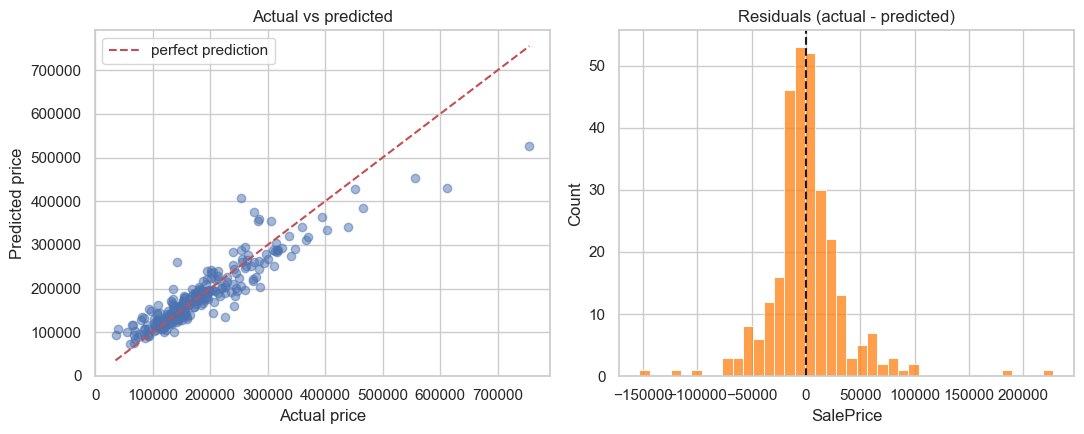

In [11]:
best = "Random Forest"
y_pred = preds[best]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(y_test, y_pred, alpha=0.5)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--", label="perfect prediction")
ax[0].set_xlabel("Actual price"); ax[0].set_ylabel("Predicted price")
ax[0].set_title("Actual vs predicted"); ax[0].legend()

residuals = y_test - y_pred
sns.histplot(residuals, bins=40, ax=ax[1], color="tab:orange")
ax[1].axvline(0, color="k", ls="--")
ax[1].set_title("Residuals (actual - predicted)")
plt.tight_layout()
plt.show()

In [12]:
errors = pd.DataFrame({"actual": y_test, "predicted": y_pred.round(0)})
errors["abs_error"] = (errors["actual"] - errors["predicted"]).abs()
errors["pct_error"] = (errors["abs_error"] / errors["actual"] * 100).round(1)
print("Worst 5 predictions:")
errors.sort_values("abs_error", ascending=False).head(5)

Worst 5 predictions:


,actual,predicted,abs_error,pct_error
691,755000.0,527438.0,227562.0,30.1
898,611657.0,429671.0,181986.0,29.8
581,253293.0,406361.0,153068.0,60.4
588,143000.0,261756.0,118756.0,83.0
1046,556581.0,453454.0,103127.0,18.5


## 9. What drives the price? (feature importance)

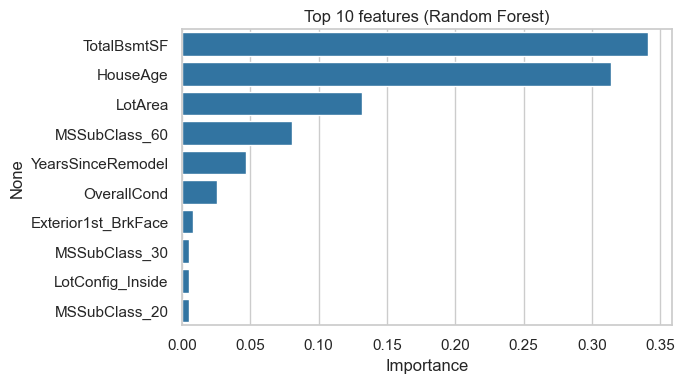

In [13]:
rf = models["Random Forest"][0]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top = importance.head(10)
plt.figure(figsize=(7, 4))
sns.barplot(x=top.values, y=top.index, color="tab:blue")
plt.title("Top 10 features (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 10. Conclusions

- Training on only the rows with a real `SalePrice` (instead of mean-filling the missing target) gives a **trustworthy** evaluation.
- Random Forest clearly beats the linear baseline, so the price depends on non-linear patterns (area, age, basement size, etc.).
- **Limitations:** only 11 raw features are available (no living area, no neighbourhood, no quality rating), so there is a ceiling on accuracy. The data is also from one city and period (up to 2010).
- **Next steps:** hyperparameter tuning (`GridSearchCV`), gradient boosting (XGBoost / LightGBM), and richer features.